In [ ]:
install.packages("pivottabler")


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
library(IRdisplay)

In [ ]:
library(pivottabler)

pop_raw <- read.csv("World-population-by-countries-dataset.csv", check.names = FALSE)

pop_long <- pop_raw %>%
  pivot_longer(
    cols = matches("^\\d{4}$"),
    names_to = "Year",
    values_to = "Population"
  ) %>%
  mutate(
    Year = as.integer(Year),
    Population = as.numeric(Population),
    Decade = paste0(floor(Year / 10) * 10, "s"),
    Pop_Millions = Population / 1e6
  ) %>%
  filter(!is.na(Population))

# Выбираем несколько крупных стран для наглядной сводной таблицы и графиков
selected_countries <- c("China", "India", "United States", "Indonesia", "Russian Federation")

pop_sub <- pop_long %>%
  filter(`Country Name` %in% selected_countries, Year %in% c(1980, 1990, 2000, 2010, 2020))

# Отображение сводной таблицы с помощью pivottabler
pt <- PivotTable$new()
pt$addData(pop_sub)
pt$addRowDataGroups("Country Name", totalCaption = "All Countries")
pt$addColumnDataGroups("Year", totalCaption = "All Years")
pt$defineCalculation(
  calculationName = "MeanPopM",
  caption = "Pop (M)",
  summariseExpression = "mean(Pop_Millions, na.rm = TRUE)",
  format = "%.1f"
)
pt$evaluatePivot()
pt

                    1980   1990    2000    2010    2020    All Years  
China               981.2  1135.2  1262.6  1337.7  1411.1     1225.6  
India               699.0   873.3  1056.6  1234.3  1380.0     1048.6  
Indonesia           147.4   181.4   211.5   241.8   273.5      211.1  
Russian Federation  139.0   148.0   146.6   142.8   144.1      144.1  
United States       227.2   249.6   282.2   309.3   331.5      280.0  
All Countries       438.8   517.5   591.9   653.2   708.0      581.9  

In [ ]:
library(pivottabler)

# 1. Стиль из методички (бордовый + кремовый) через PivotTable$new()
pt_style_doc <- PivotTable$new(
  tableStyle = list("border-color" = "maroon"),
  headingStyle = list(
    "color" = "cornsilk",
    "background-color" = "maroon",
    "font-style" = "italic",
    "border-color" = "maroon"
  ),
  cellStyle = list(
    "color" = "maroon",
    "background-color" = "cornsilk",
    "border-color" = "maroon"
  ),
  totalStyle = list(
    "color" = "maroon",
    "background-color" = "cornsilk",
    "border-color" = "maroon",
    "font-weight" = "bold"
  )
)

pt_style_doc$addData(pop_sub)
pt_style_doc$addRowDataGroups("Country Name", totalCaption = "Total")
pt_style_doc$addColumnDataGroups("Year", totalCaption = "Total")
pt_style_doc$defineCalculation(
  calculationName = "MeanPopM",
  caption = "Pop (M)",
  summariseExpression = "mean(Pop_Millions, na.rm = TRUE)",
  format = "%.1f"
)
pt_style_doc$renderPivot()
# Сохраняем таблицу в HTML-файл и выводим в ячейке Colab
pt_style_doc$saveHtml("pivot_table_1.html")
display_html(file = "pivot_table_1.html")

# 2. Дополнительно: подсветка конкретных ячеек по условию (например, >= 1000 млн чел.)
cells <- pt_style_doc$findCells(
  minValue = 1000,
  includeNull = FALSE,
  includeNA = FALSE
)
pt_style_doc$setStyling(
  cells = cells,
  declarations = list(
    "background-color" = "#ffe082",
    "color" = "#000000",
    "font-weight" = "bold"
  )
)
pt_style_doc$evaluatePivot()
pt_style_doc$saveHtml("pivot_table_2.html")
display_html(file = "pivot_table_2.html")

HTML widgets cannot be represented in plain text (need html)

,1980,1990,2000,2010,2020,Total
China,981.2,1135.2,1262.6,1337.7,1411.1,1225.6
India,699.0,873.3,1056.6,1234.3,1380.0,1048.6
Indonesia,147.4,181.4,211.5,241.8,273.5,211.1
Russian Federation,139.0,148.0,146.6,142.8,144.1,144.1
United States,227.2,249.6,282.2,309.3,331.5,280.0
Total,438.8,517.5,591.9,653.2,708.0,581.9


,1980,1990,2000,2010,2020,Total
China,981.2,1135.2,1262.6,1337.7,1411.1,1225.6
India,699.0,873.3,1056.6,1234.3,1380.0,1048.6
Indonesia,147.4,181.4,211.5,241.8,273.5,211.1
Russian Federation,139.0,148.0,146.6,142.8,144.1,144.1
United States,227.2,249.6,282.2,309.3,331.5,280.0
Total,438.8,517.5,591.9,653.2,708.0,581.9


In [ ]:
library(IRdisplay)
# Стиль  через PivotTable$new()
pt_styled <- PivotTable$new(
  tableStyle = list("border-color" = "maroon"),
  headingStyle = list(
    "color" = "cornsilk",
    "background-color" = "maroon",
    "font-style" = "italic",
    "border-color" = "maroon"
  ),
  cellStyle = list(
    "color" = "maroon",
    "background-color" = "cornsilk",
    "border-color" = "maroon"
  ),
  totalStyle = list(
    "color" = "maroon",
    "background-color" = "cornsilk",
    "border-color" = "maroon",
    "font-weight" = "bold"
  )
)
pt_styled$addData(pop_sub)
pt_styled$addRowDataGroups("Country Name", totalCaption = "Total")
pt_styled$addColumnDataGroups("Year", totalCaption = "Total")
pt_styled$defineCalculation(
  calculationName = "MeanPopM",
  caption = "Pop (M)",
  summariseExpression = "mean(Pop_Millions, na.rm = TRUE)",
  format = "%.1f"
)
pt_styled$renderPivot()
# Сохраняем таблицу в HTML-файл и выводим в ячейке Colab
pt_styled$saveHtml("pivot_table.html")
display_html(file = "pivot_table.html")

HTML widgets cannot be represented in plain text (need html)

,1980,1990,2000,2010,2020,Total
China,981.2,1135.2,1262.6,1337.7,1411.1,1225.6
India,699.0,873.3,1056.6,1234.3,1380.0,1048.6
Indonesia,147.4,181.4,211.5,241.8,273.5,211.1
Russian Federation,139.0,148.0,146.6,142.8,144.1,144.1
United States,227.2,249.6,282.2,309.3,331.5,280.0
Total,438.8,517.5,591.9,653.2,708.0,581.9


                    1980   1990    2000    2010    2020    All Years  
China               981.2  1135.2  1262.6  1337.7  1411.1     1225.6  
India               699.0   873.3  1056.6  1234.3  1380.0     1048.6  
Indonesia           147.4   181.4   211.5   241.8   273.5      211.1  
Russian Federation  139.0   148.0   146.6   142.8   144.1      144.1  
United States       227.2   249.6   282.2   309.3   331.5      280.0  
All Countries       438.8   517.5   591.9   653.2   708.0      581.9  

HTML widgets cannot be represented in plain text (need html)

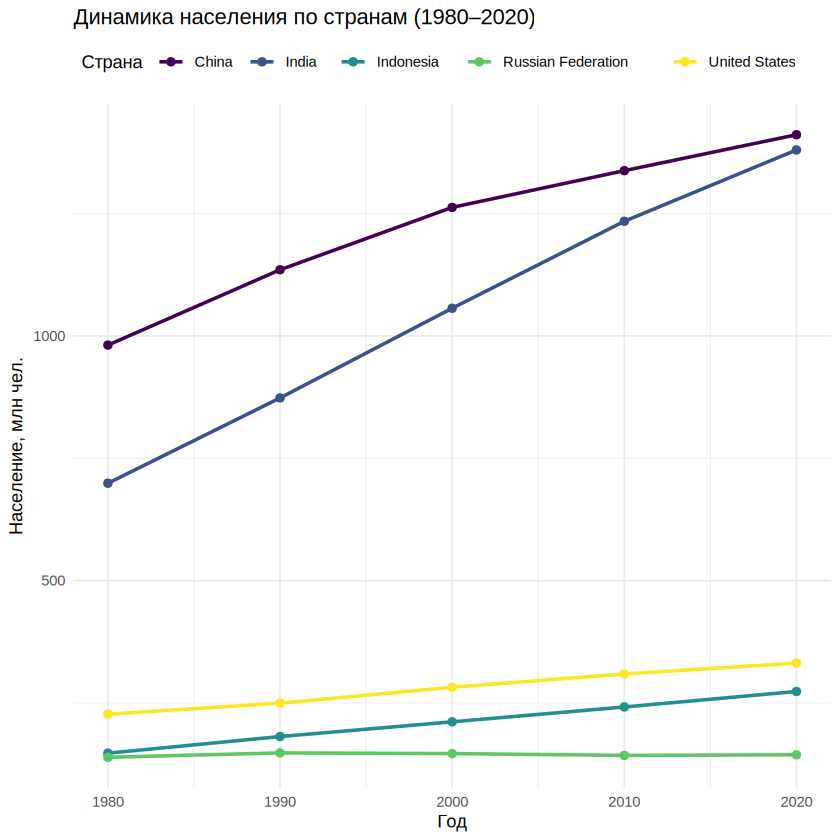

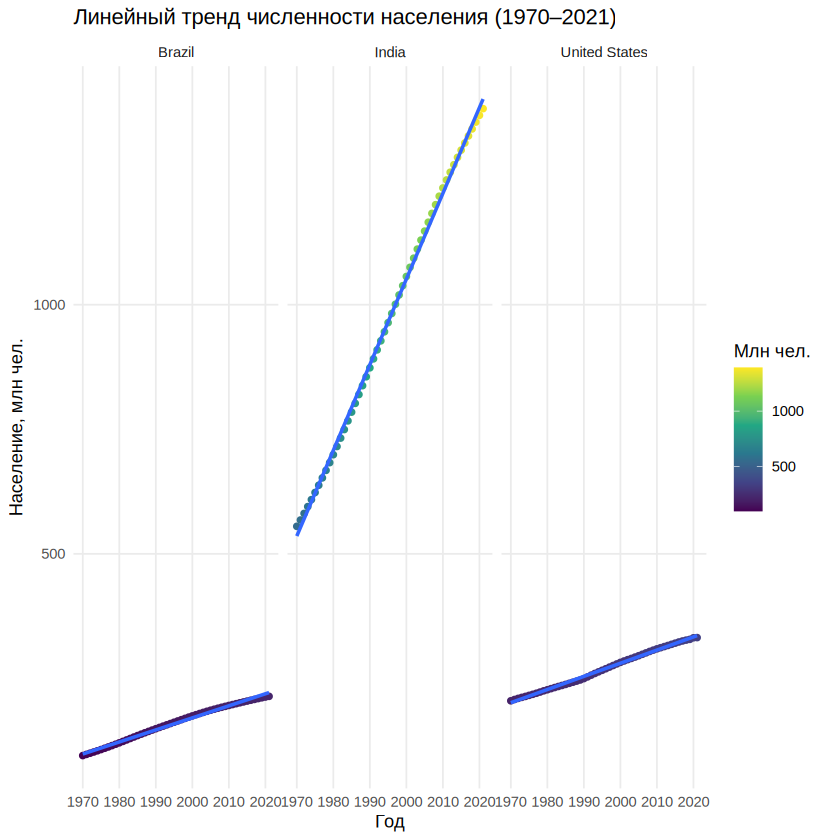

In [ ]:
# 1. Установка (при необходимости) и подключение пакетов
# install.packages(c("pivottabler", "dplyr", "tidyr", "ggplot2", "openxlsx", "flextable", "officer"))

library(pivottabler)
library(dplyr)
library(tidyr)
library(ggplot2)
library(openxlsx)
library(flextable)
library(officer)

# 2. Загрузка и трансформация данных (пункт 1 и 2 задания)
# Переводим широкую таблицу (годы 1960-2021 в столбцах) в длинный формат для удобства анализа
pop_raw <- read.csv("World-population-by-countries-dataset.csv", check.names = FALSE)

pop_long <- pop_raw %>%
  pivot_longer(
    cols = matches("^\\d{4}$"),
    names_to = "Year",
    values_to = "Population"
  ) %>%
  mutate(
    Year = as.integer(Year),
    Population = as.numeric(Population),
    Decade = paste0(floor(Year / 10) * 10, "s"),
    Pop_Millions = Population / 1e6
  ) %>%
  filter(!is.na(Population))

# Выбираем несколько крупных стран для наглядной сводной таблицы и графиков
selected_countries <- c("China", "India", "United States", "Indonesia", "Russian Federation")

pop_sub <- pop_long %>%
  filter(`Country Name` %in% selected_countries, Year %in% c(1980, 1990, 2000, 2010, 2020))

# Отображение сводной таблицы в RStudio с помощью pivottabler (в стиле примеров методички)
pt <- PivotTable$new()
pt$addData(pop_sub)
pt$addRowDataGroups("Country Name", totalCaption = "All Countries")
pt$addColumnDataGroups("Year", totalCaption = "All Years")
pt$defineCalculation(
  calculationName = "MeanPopM",
  caption = "Pop (M)",
  summariseExpression = "mean(Pop_Millions, na.rm = TRUE)",
  format = "%.1f"
)
pt$evaluatePivot()
pt


# 3. Форматирование стилями и выгрузка в Excel и Word (пункт 3 задания)
pt_styled <- PivotTable$new(
  tableStyle = list("border-color" = "maroon"),
  headingStyle = list(
    "color" = "cornsilk",
    "background-color" = "maroon",
    "font-style" = "italic",
    "border-color" = "maroon"
  ),
  cellStyle = list(
    "color" = "maroon",
    "background-color" = "cornsilk",
    "border-color" = "maroon"
  ),
  totalStyle = list(
    "color" = "maroon",
    "background-color" = "cornsilk",
    "border-color" = "maroon",
    "font-weight" = "bold"
  )
)
pt_styled$addData(pop_sub)
pt_styled$addRowDataGroups("Country Name", totalCaption = "Total")
pt_styled$addColumnDataGroups("Year", totalCaption = "Total")
pt_styled$defineCalculation(
  calculationName = "MeanPopM",
  caption = "Pop (M)",
  summariseExpression = "mean(Pop_Millions, na.rm = TRUE)",
  format = "%.1f"
)
pt_styled$renderPivot()

# Выгрузка в Excel через openxlsx (как в разделе 3.2 методички)
wb <- createWorkbook(creator = Sys.getenv("USERNAME"))
addWorksheet(wb, "PopulationPivot")
pt_styled$writeToExcelWorksheet(
  wb = wb,
  wsName = "PopulationPivot",
  topRowNumber = 2,
  leftMostColumnNumber = 2,
  applyStyles = TRUE
)
saveWorkbook(wb, file = "population_pivot.xlsx", overwrite = TRUE)

# Выгрузка сводной таблицы в Word через flextable и officer
# Преобразуем сводную таблицу в обычный data.frame и оформляем как таблицу Word
pivot_df <- pt_styled$asDataFrame()
ft <- flextable(pivot_df) %>%
  theme_box() %>%
  bold(part = "header") %>%
  autofit()

doc <- read_docx() %>%
  body_add_par("Сводная таблица населения (млн чел.)", style = "heading 1") %>%
  body_add_flextable(ft)

print(doc, target = "population_pivot.docx")


# 4. Визуализация результатов с помощью ggplot2 (пункт 4 задания)
# График 1: Динамика численности населения по годам с линией тренда
p1 <- ggplot(pop_sub, aes(x = Year, y = Pop_Millions, colour = `Country Name`)) +
  geom_line(linewidth = 1) +
  geom_point(size = 2) +
  scale_colour_viridis_d() +
  labs(
    title = "Динамика населения по странам (1980–2020)",
    x = "Год",
    y = "Население, млн чел.",
    colour = "Страна"
  ) +
  theme_minimal() +
  theme(legend.position = "top")

print(p1)

# График 2: Сравнение по десятилетиям с разбивкой на фасеты (по аналогии с методичкой)
pop_facets <- pop_long %>%
  filter(`Country Name` %in% c("India", "United States", "Brazil"), Year >= 1970)

p2 <- ggplot(pop_facets, aes(x = Year, y = Pop_Millions)) +
  geom_point(aes(colour = Pop_Millions), size = 1.5) +
  geom_smooth(formula = y ~ x, method = "lm", se = FALSE) +
  scale_colour_viridis_c() +
  facet_grid(~ `Country Name`) +
  labs(
    title = "Линейный тренд численности населения (1970–2021)",
    x = "Год",
    y = "Население, млн чел.",
    colour = "Млн чел."
  ) +
  theme_minimal() +
  theme(panel.grid.minor = element_blank())

print(p2)

<ggplot2::labels> List of 4
 $ x     : chr "Год"
 $ y     : chr "Население, млн чел."
 $ colour: chr "Страна"
 $ title : chr "Динамика населения по странам (1980–2020)"

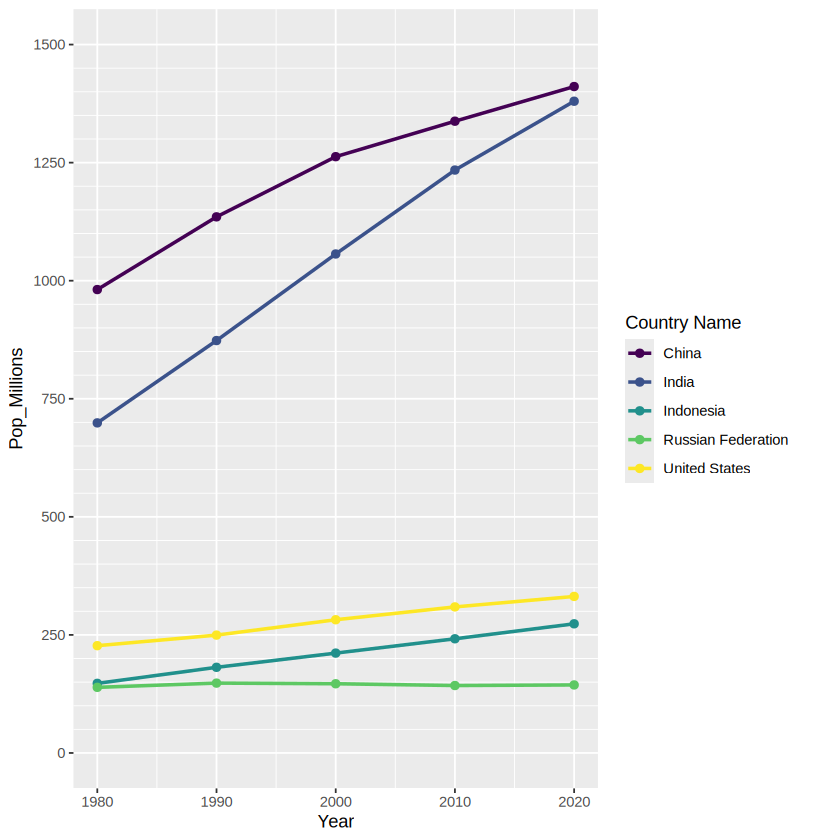

In [52]:
p1 <- ggplot(pop_sub, aes(x = Year, y = Pop_Millions, colour = `Country Name`)) +
  geom_line(linewidth = 1) +
  geom_point(size = 2) +
  scale_colour_viridis_d() +
    scale_y_continuous(
    breaks = seq(0, 1500, by = 250),
    minor_breaks = seq(0, 1500, by = 50),
    limits = c(0, 1500)
  )
  labs(
    title = "Динамика населения по странам (1980–2020)",
    x = "Год",
    y = "Население, млн чел.",
    colour = "Страна"
  )


print(p1)

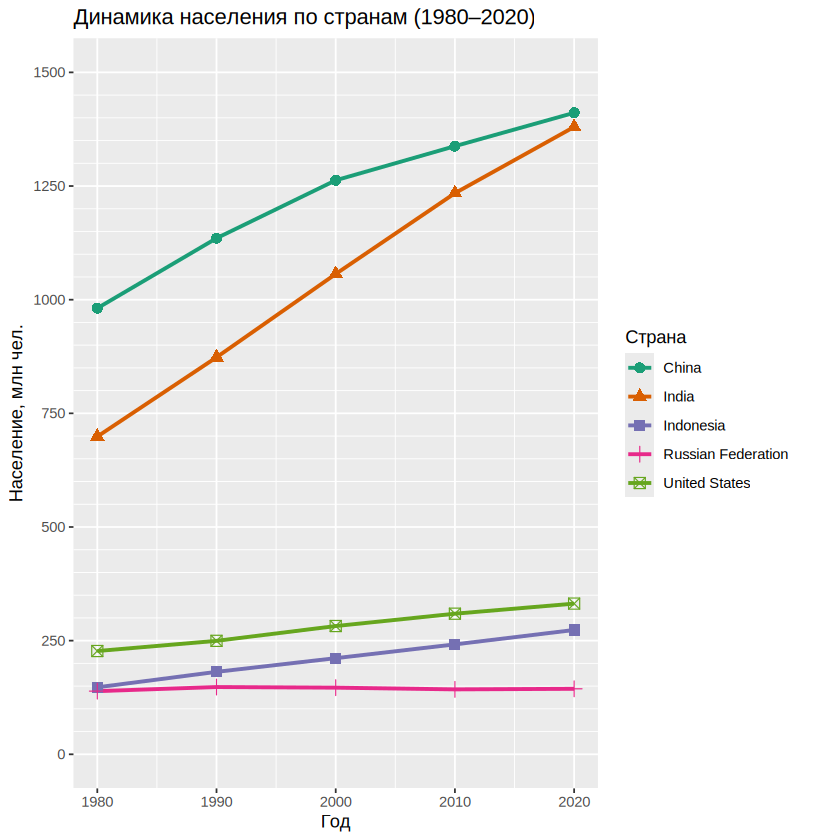

In [48]:
library("ggplot2")

# 4. Визуализация результатов с помощью ggplot2
# График 1: Динамика численности населения по странам (1980–2020)
p1 <- ggplot(pop_sub,aes(x = Year,y = Pop_Millions,colour = `Country Name`,
    shape = `Country Name`
  )
) +
  geom_line(linewidth = 1.1) +
  geom_point(size = 2.8) +
  scale_colour_brewer(palette = "Dark2") +
  scale_x_continuous(
    breaks = seq(1980, 2020, by = 10),
    minor_breaks = seq(1980, 2020, by = 5)
  ) +
  scale_y_continuous(
    breaks = seq(0, 1500, by = 250),
    minor_breaks = seq(0, 1500, by = 50),
    limits = c(0, 1500)
  ) +
  labs(
    title = "Динамика населения по странам (1980–2020)",
    x = "Год",
    y = "Население, млн чел.",
    colour = "Страна",
    shape = "Страна"
  )

p1

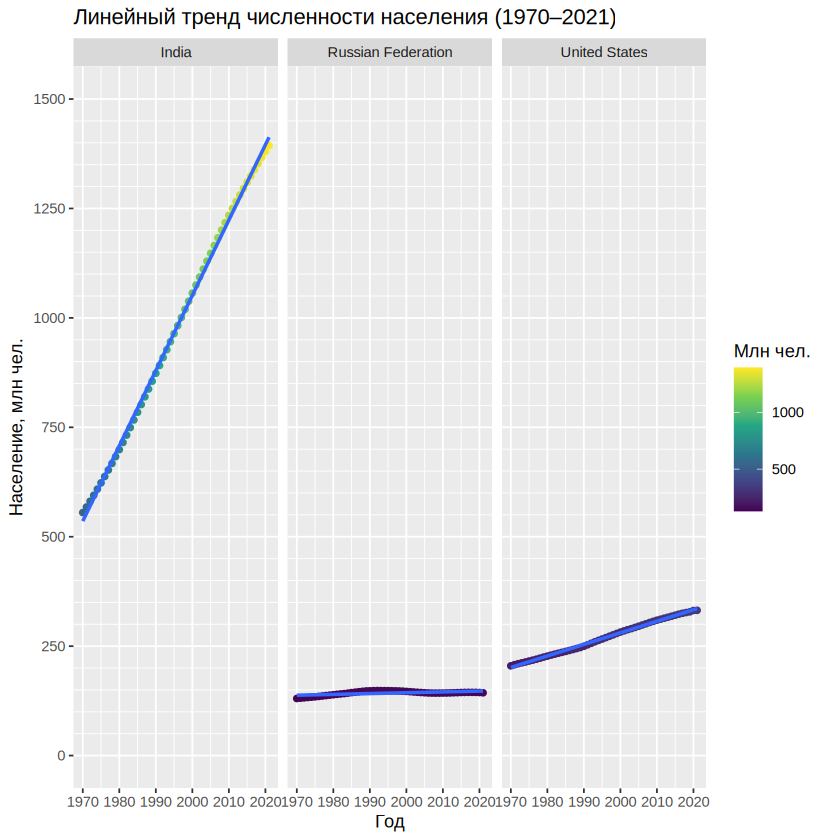

In [57]:
# График 2: Сравнение по десятилетиям с разбивкой на фасеты (по аналогии с методичкой)
pop_facets <- pop_long %>%
  filter(`Country Name` %in% c("India", "United States", "Russian Federation"), Year >= 1970)

p2 <- ggplot(pop_facets, aes(x = Year, y = Pop_Millions)) +
  geom_point(aes(colour = Pop_Millions), size = 1.5) +
  geom_smooth(formula = y ~ x, method = "lm", se = FALSE) +
  scale_colour_viridis_c() +
  facet_grid(~ `Country Name`) +
  labs(
    title = "Линейный тренд численности населения (1970–2021)",
    x = "Год",
    y = "Население, млн чел.",
    colour = "Млн чел."
  )+
    scale_y_continuous(
    breaks = seq(0, 1500, by = 250),
    minor_breaks = seq(0, 1500, by = 50),
    limits = c(0, 1500)
  )


print(p2)